---
title: Multivariate > Choice conjoint
jupyter: python3
---

<div class="alert alert-info">Estimate part-worths, willingness to pay and market shares from a choice-based conjoint (CBC) survey, where respondents choose one product from each set of alternatives.</div>

<!-- pyrsm-teaching-note: roadmap -->
## Teaching Roadmap

In a ratings-based conjoint (`rsm.multivariate.conjoint`) respondents score every profile. In a **choice-based conjoint** they do what customers do in a store: in each *choice task* they see a few product profiles side by side and pick the one they would buy. Choosing is easier and more realistic than rating, and the results translate directly into market shares.

`rsm.multivariate.conjoint_choice` fits a **conditional (multinomial) logit**. Each profile's utility is the sum of the part-worths of its attribute levels, and the probability that it is chosen is its share of the utilities within the task:

$$P(\text{profile } j \text{ chosen in task } t) = \frac{e^{u_j}}{\sum_{k \in t} e^{u_k}}$$

Students should learn to (1) recognize the long "choice task" data format, (2) interpret part-worths, odds ratios and importance weights from a choice model, (3) convert part-worths to **willingness to pay**, (4) simulate **market shares** for a set of competing products, (5) look for **segments** whose preferences differ, and (6) know the limits of the logit model (IIA).

This notebook is the same analysis as *Multivariate > Conjoint > Choice conjoint* in Radiant-AI, where every step below is a few clicks.

In [1]:
import polars as pl
import pyrsm as rsm

In [2]:
## setup pyrsm for autoreload
%reload_ext autoreload
%autoreload 2
%aimport pyrsm

## The Minivan Choice Study

This example is adapted from the minivan study in Chapman and Feit, *R for Marketing Research and Analytics* (2nd ed., Springer, 2019), chapter 13. A car maker wants to know which minivan features buyers value and how a new design would sell against the competition. 200 respondents each answered 15 choice tasks; every task showed 3 minivans described by four attributes:

- `seat` — number of seats (6, 7, 8)
- `cargo` — cargo space (2ft, 3ft)
- `eng` — engine (gas, hyb = hybrid, elec = electric)
- `price` — price in $1,000s (30, 35, 40)

The data were simulated for this example from known preferences (`scripts/generate_minivan_example.py` in pyrsm), so the estimates differ somewhat from the book's. About 30% of the respondents carpool (`carpool`), and carpoolers were simulated to like extra seats. The dataset description is embedded in the parquet file and also available as `minivan_description.md`.

In [3]:
def load_mv(name):
    """Load a multivariate example dataset from GitHub, with a local fallback."""
    url = (
        "https://github.com/radiant-ai-hub/pyrsm/raw/refs/heads/main/"
        f"examples/data/multivariate/{name}.parquet"
    )
    try:
        return pl.read_parquet(url)
    except Exception:
        from pathlib import Path

        for base in [Path.cwd(), *Path.cwd().parents]:
            p = base / "examples" / "data" / "multivariate" / f"{name}.parquet"
            if p.exists():
                return pl.read_parquet(p)
        raise


minivan = load_mv("minivan")
minivan_market = load_mv("minivan_market")
minivan.head(6)

resp,ques,task,alt,carpool,seat,cargo,eng,price,choice
i64,i64,i64,i64,enum,enum,enum,enum,i32,i64
1,1,1,1,"""no""","""8""","""2ft""","""hyb""",35,0
1,1,1,2,"""no""","""6""","""3ft""","""elec""",35,1
1,1,1,3,"""no""","""8""","""2ft""","""elec""",30,0
1,2,2,1,"""no""","""6""","""3ft""","""hyb""",35,0
1,2,2,2,"""no""","""8""","""3ft""","""gas""",35,0
1,2,2,3,"""no""","""7""","""3ft""","""elec""",35,1


The data are in **long** format: one row per minivan per task, so 3,000 tasks × 3 minivans = 9,000 rows.

- `resp` — respondent id; `ques` — question number for the respondent (1–15)
- `task` — the choice-task id, unique across respondents (1–3,000). This is the grouping unit of the model
- `alt` — the alternative (position) within a task (1–3)
- `choice` — 1 if the respondent chose this minivan, else 0

In the first task respondent 1, who does not carpool, chose alternative 2 (6 seats, 3ft, electric, $35K) over two 8-seat minivans.

Price is **numeric**, so the model estimates one price slope; that slope is what willingness to pay is computed from. The other attributes are categorical (polars `Enum`), so each level gets its own part-worth relative to the first level (6 seats, 2ft, gas).

Before estimating, check that every task has exactly one chosen alternative, and that `task` (not `ques`) identifies a task:

In [4]:
print(minivan.group_by("task").agg(pl.col("choice").sum())["choice"].unique().to_list())
print(minivan.group_by("ques").agg(pl.col("choice").sum())["choice"].unique().to_list())

[1]
[200]


Every `task` has one choice. Every `ques` value has 200 choices (one per respondent), which is why `ques` cannot be the task id: it would merge the tasks of 200 different respondents into one.

## a. Estimate the Choice Model

Which features do buyers value, and which do they avoid? `rvar` is the choice indicator with `lev="1"` the value that means "chosen", `evar` the attributes, `id` the choice-task id and `alt` the alternative id.

In [5]:
cc = rsm.multivariate.conjoint_choice(
    {"minivan": minivan},
    rvar="choice",
    lev="1",
    evar=["seat", "cargo", "eng", "price"],
    id="task",
    alt="alt",
)
cc.summary()

Conjoint choice model (conditional logit)
Data                 : minivan
Response variable    : choice
Level                : 1
Choice task id       : task
Alternative id       : alt
Explanatory variables: seat, cargo, eng, price
Null hyp.: There is no effect of x on the choice of choice
Alt. hyp.: There is an effect of x on the choice of choice

┌────────────┬───────┬────────┬─────────────┬───────────┬─────────┬─────────┬─────┐
│ index      ┆ OR    ┆ OR%    ┆ coefficient ┆ std.error ┆ z.value ┆ p.value ┆     │
╞════════════╪═══════╪════════╪═════════════╪═══════════╪═════════╪═════════╪═════╡
│ seat[7]    ┆ 0.565 ┆ -43.5% ┆ -0.57       ┆ 0.061     ┆ -9.311  ┆ < .001  ┆ *** │
│ seat[8]    ┆ 0.641 ┆ -35.9% ┆ -0.445      ┆ 0.061     ┆ -7.319  ┆ < .001  ┆ *** │
│ cargo[3ft] ┆ 1.522 ┆ 52.2%  ┆ 0.42        ┆ 0.05      ┆ 8.338   ┆ < .001  ┆ *** │
│ eng[hyb]   ┆ 0.458 ┆ -54.2% ┆ -0.78       ┆ 0.059     ┆ -13.12  ┆ < .001  ┆ *** │
│ eng[elec]  ┆ 0.205 ┆ -79.5% ┆ -1.585      ┆ 0.068     ┆ -23.2

All coefficients are significant. Relative to the base minivan (6 seats, 2ft cargo, gas engine):

- 3ft of cargo space makes a minivan more attractive: the odds of choosing it are 1.52 times (52% higher) those of the same minivan with 2ft;
- a hybrid (OR 0.46) and especially an electric engine (OR 0.21, 79% lower odds) make it less attractive;
- on average buyers prefer 6 seats over 7 (OR 0.57) or 8 (OR 0.64), but see section **f**: this average hides two segments;
- each extra $1,000 lowers the odds of choice by 14% (OR 0.858). A $5,000 price increase multiplies the odds by $0.858^5 \approx 0.46$.

The **importance weights** are the range of each attribute's part-worths (for price: the slope times the range of prices tested) divided by the sum of the ranges. The engine (.385) and price (.374) matter most over the levels tested; seating (.139) and cargo (.102) matter less.

**Fit.** McFadden's pseudo R² (0.196) compares the log-likelihood to a model where every alternative is equally likely; values of 0.2 to 0.4 indicate a good fit for choice data. The model predicts the chosen minivan in 58.5% of tasks, against 33.3% by guessing among 3 (the *hit rate*).

The part-worths and importance weights are also available as data frames:

In [6]:
cc.PW

Attributes,Levels,PW
str,str,f64
"""seat""","""6""",0.0
"""seat""","""7""",-0.570436
"""seat""","""8""",-0.445111
"""cargo""","""2ft""",0.0
"""cargo""","""3ft""",0.420322
"""eng""","""gas""",0.0
"""eng""","""hyb""",-0.780185
"""eng""","""elec""",-1.585133
"""price""","""(slope)""",-0.153654


In [7]:
cc.IW

Attributes,IW
str,f64
"""seat""",0.13871
"""cargo""",0.102208
"""eng""",0.385449
"""price""",0.373634


## b. Willingness to Pay

How much more would buyers pay for 3ft of cargo space? How much less for an electric engine?

Part-worths are in "utility" units. Dividing a part-worth by minus the price coefficient converts it to money: the price change that leaves the utility unchanged. Price is in $1,000s, so the WTP column is in $1,000s too.

In [8]:
cc.wtp(price="price", dec=3)

Attributes,Levels,PW,WTP
str,str,f64,f64
"""seat""","""6""",0.0,0.0
"""seat""","""7""",-0.57,-3.712
"""seat""","""8""",-0.445,-2.897
"""cargo""","""2ft""",0.0,0.0
"""cargo""","""3ft""",0.42,2.736
"""eng""","""gas""",0.0,0.0
"""eng""","""hyb""",-0.78,-5.078
"""eng""","""elec""",-1.585,-10.316


- 3ft of cargo space is worth $0.420 / 0.154 \approx$ **\$2,736** (the book reports about \$2,750);
- a hybrid engine needs a price cut of about \$5,078, and an electric engine about **\$10,316**, to be as attractive as gas;
- for the average buyer, 7 seats are worth \$3,712 *less* than 6.

WTP assumes the price effect is linear over the range tested (\$30K to \$40K). Do not extrapolate far outside that range.

## c. Market Simulation

The car maker plans to launch minivan 1 (7 seats, 2ft, hybrid, \$30K) against five competitors. What share of the choices would each minivan get? `minivan_market` describes the six minivans (the designs in the book's share simulation):

In [9]:
minivan_market

product,seat,cargo,eng,price
i64,enum,enum,enum,i32
1,"""7""","""2ft""","""hyb""",30
2,"""6""","""2ft""","""gas""",30
3,"""8""","""2ft""","""gas""",30
4,"""7""","""3ft""","""gas""",40
5,"""6""","""2ft""","""elec""",40
6,"""7""","""2ft""","""hyb""",35


`minivan_market` has no `task` column, so `predict` treats all six rows as one market. `prediction` is each minivan's predicted share:

In [10]:
shares = cc.predict(minivan_market, dec=3)
shares

seat,cargo,eng,price,utility,prediction
enum,enum,enum,i32,f64,f64
"""7""","""2ft""","""hyb""",30,-5.96,0.115
"""6""","""2ft""","""gas""",30,-4.61,0.445
"""8""","""2ft""","""gas""",30,-5.055,0.285
"""7""","""3ft""","""gas""",40,-6.296,0.082
"""6""","""2ft""","""elec""",40,-7.731,0.02
"""7""","""2ft""","""hyb""",35,-6.729,0.053


The 6-seat gas minivan at \$30K (row 2) leads with 44.5%, the 8-seat gas minivan at \$30K follows with 28.5%, and the new hybrid gets 11.5%. Row 6 is the same hybrid at \$35K: the \$5,000 higher price cuts its share to 5.3%. The shares add to 1 within the market, and they depend on which competitors are in the market as much as on the product itself.

### Price sensitivity of the new minivan

What share would minivan 1 get at each price between \$30K and \$40K, if the five competitors stay as they are? Stack one market per price, each with its own `task` value: `predict` then computes the shares within each market separately.

In [11]:
competitors = minivan_market.filter(pl.col("product") != 6)
prices = [30, 32.5, 35, 37.5, 40]
markets = pl.concat(
    [
        competitors.with_columns(
            pl.when(pl.col("product") == 1)
            .then(pl.lit(p))
            .otherwise(pl.col("price").cast(pl.Float64))
            .alias("price"),
            pl.lit(i + 1).alias("task"),
        )
        for i, p in enumerate(prices)
    ]
)
sens = cc.predict(markets, dec=3)
sens.filter(pl.col("eng") == "hyb").select("task", "price", "prediction")

task,price,prediction
i32,f64,f64
1,30.0,0.122
2,32.5,0.086
3,35.0,0.06
4,37.5,0.042
5,40.0,0.029


The share of the new hybrid falls from 12.2% at \$30K to 2.9% at \$40K (with product 6, its own \$35K version, removed from the market, the hybrid at \$30K gets a little more than the 11.5% above). Each \$2,500 step cuts the share by about 30%. A price sensitivity curve like this is the input for a pricing decision: combine the shares with a market size and the margin at each price to find the most profitable price.

## d. What-if Predictions with a Command

How do choice shares change with engine type and price? A `cmd` dictionary lists levels: every combination is one profile, and all profiles form **one** choice set. Attributes you leave out are held at their most common level in the data (7 seats and 2ft here).

In [12]:
grid = cc.predict(cmd={"eng": ["gas", "hyb", "elec"], "price": [30, 35, 40]}, dec=3)
grid

seat,cargo,eng,price,utility,prediction
enum,enum,enum,i32,f64,f64
"""7""","""2ft""","""gas""",30,-5.18,0.358
"""7""","""2ft""","""gas""",35,-5.948,0.166
"""7""","""2ft""","""gas""",40,-6.717,0.077
"""7""","""2ft""","""hyb""",30,-5.96,0.164
"""7""","""2ft""","""hyb""",35,-6.729,0.076
"""7""","""2ft""","""hyb""",40,-7.497,0.035
"""7""","""2ft""","""elec""",30,-6.765,0.073
"""7""","""2ft""","""elec""",35,-7.533,0.034
"""7""","""2ft""","""elec""",40,-8.302,0.016


A gas minivan at \$35K (16.6%) still beats a hybrid at \$30K (16.4%): the hybrid penalty is about as large as a \$5,000 price difference, as the WTP table showed. Plot the shares by price and engine:

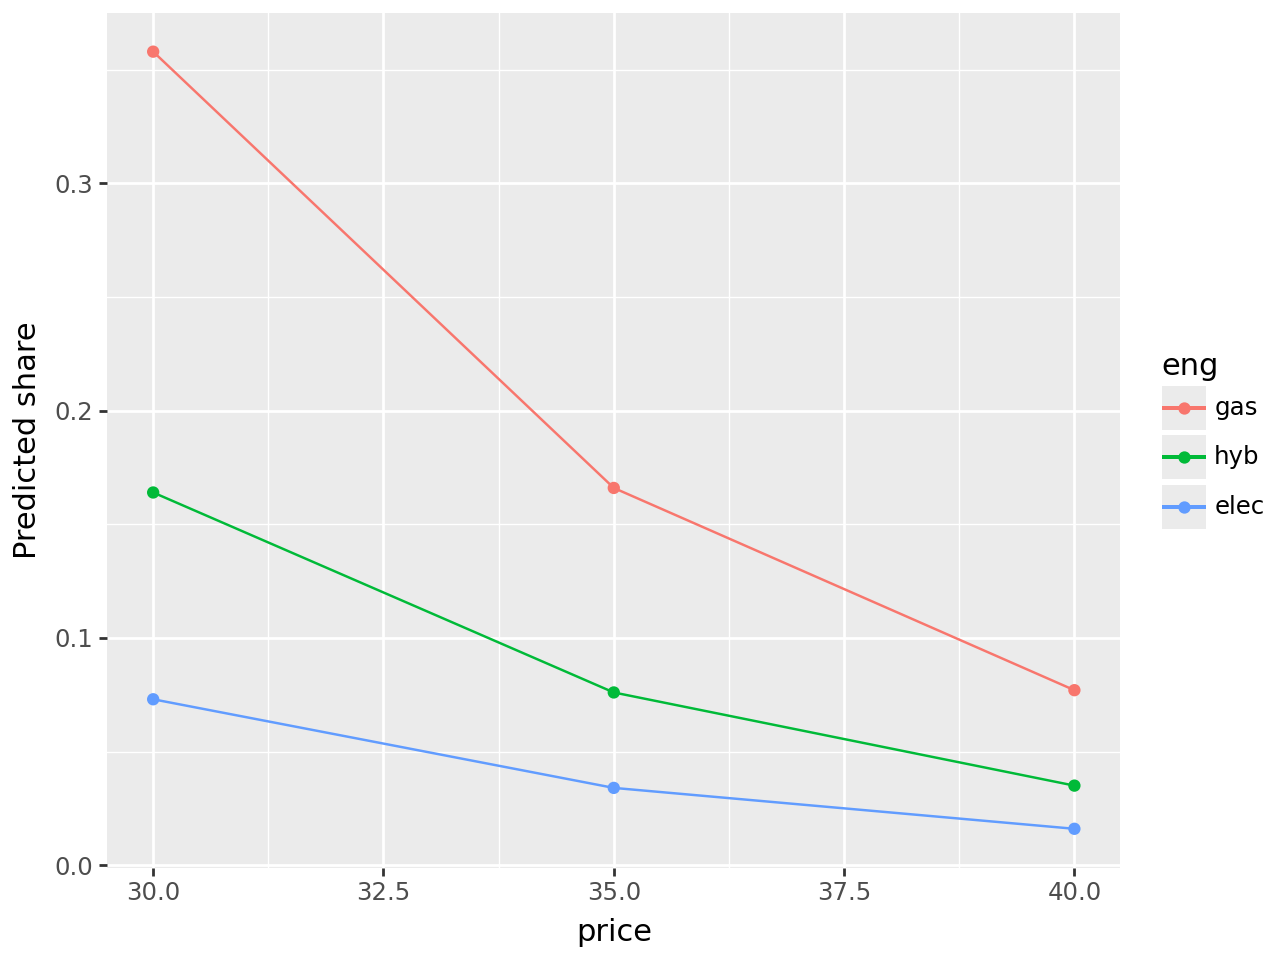

In [13]:
from plotnine import aes, geom_line, geom_point, ggplot, labs

(
    ggplot(grid, aes("price", "prediction", color="eng", group="eng"))
    + geom_line()
    + geom_point()
    + labs(y="Predicted share")
)

## e. Plots

Part-worths per categorical attribute (`scale_plot=True` puts them on one axis so their ranges can be compared), importance weights, and odds ratios with confidence intervals. An odds ratio left of the dashed line at 1 lowers the odds of choice relative to the base level; one right of it raises them.

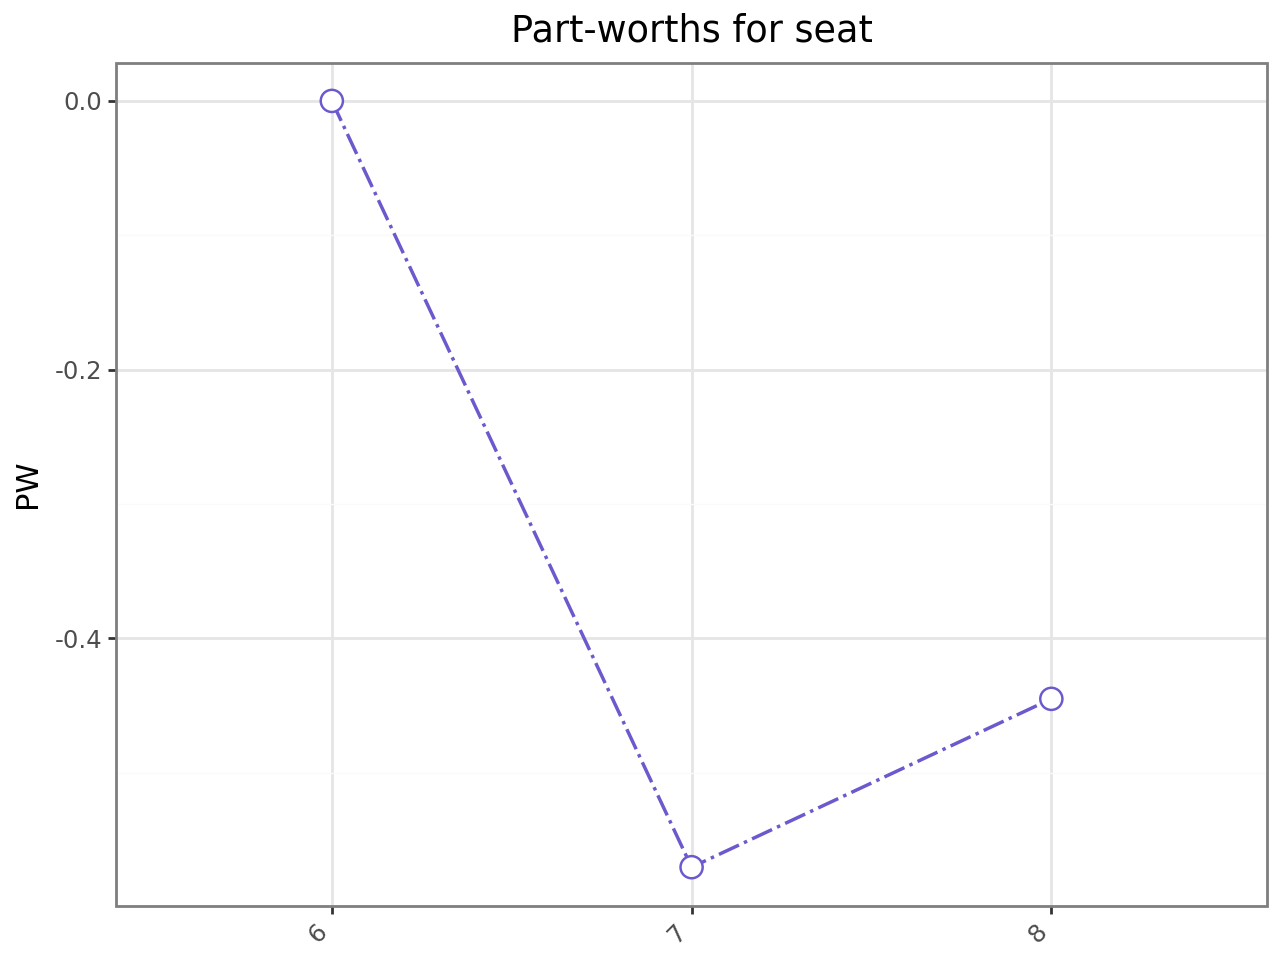

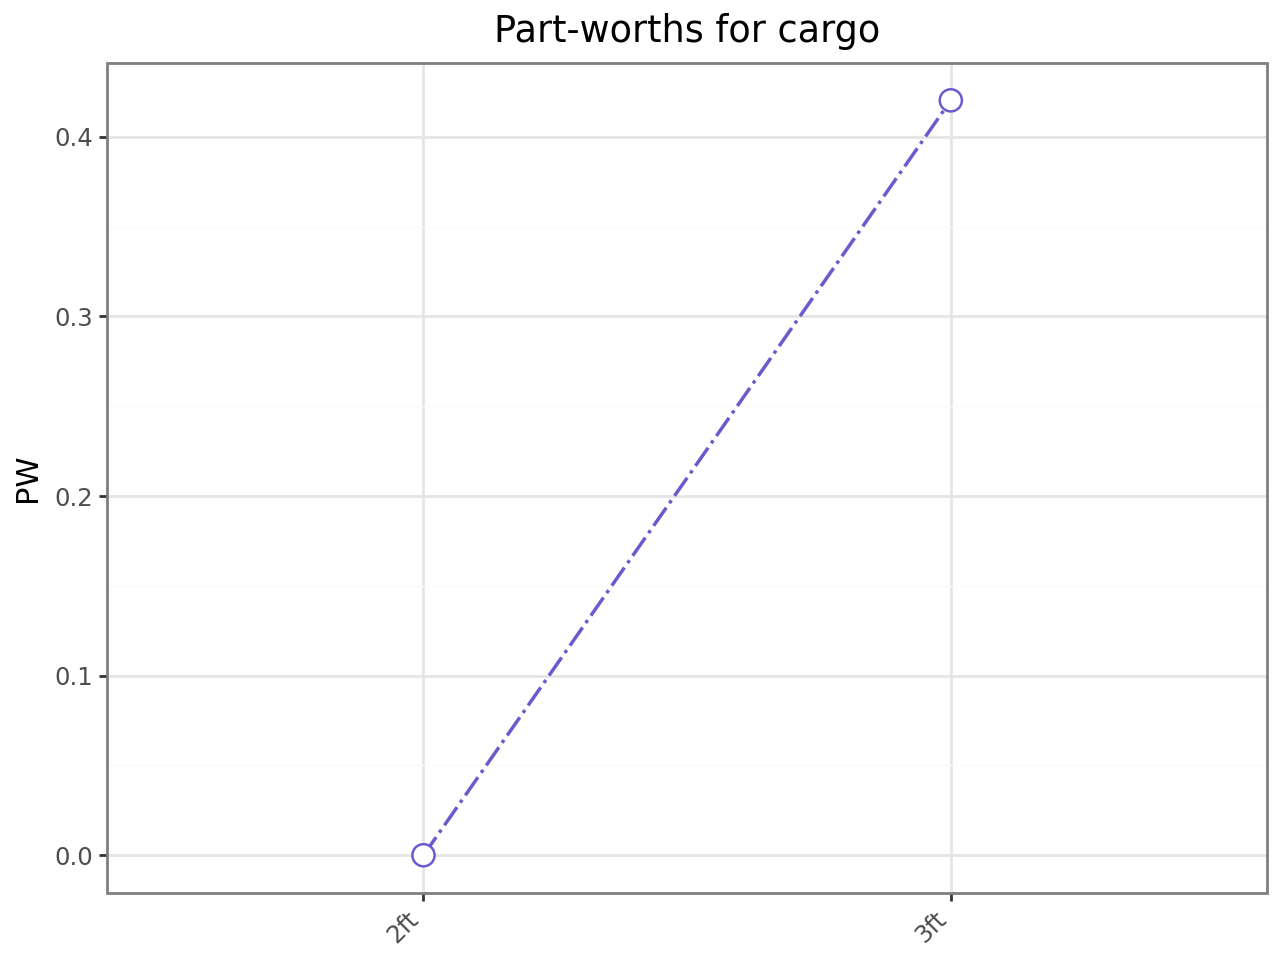

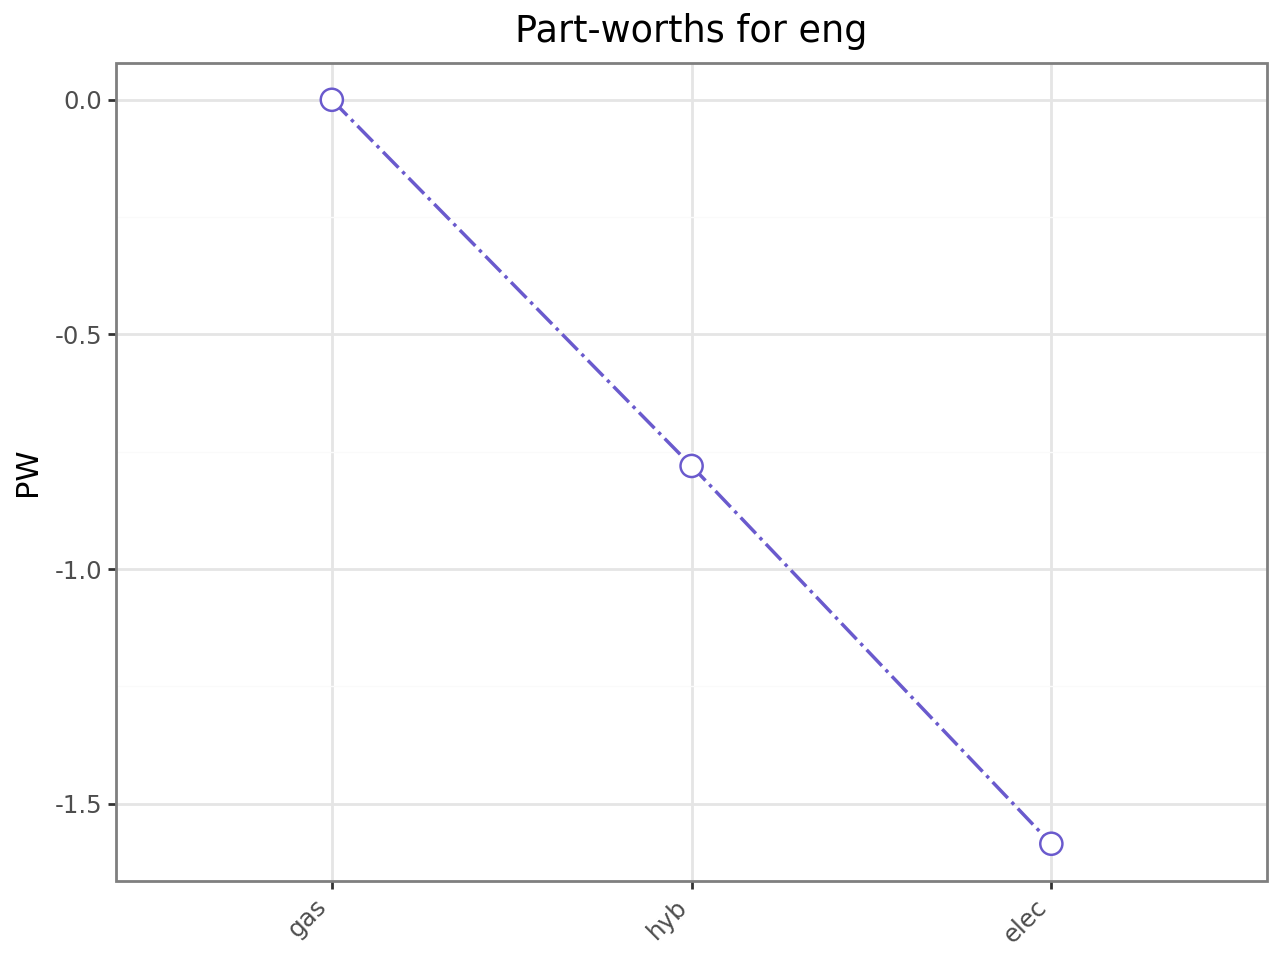

In [14]:
cc.plot(plots="pw")

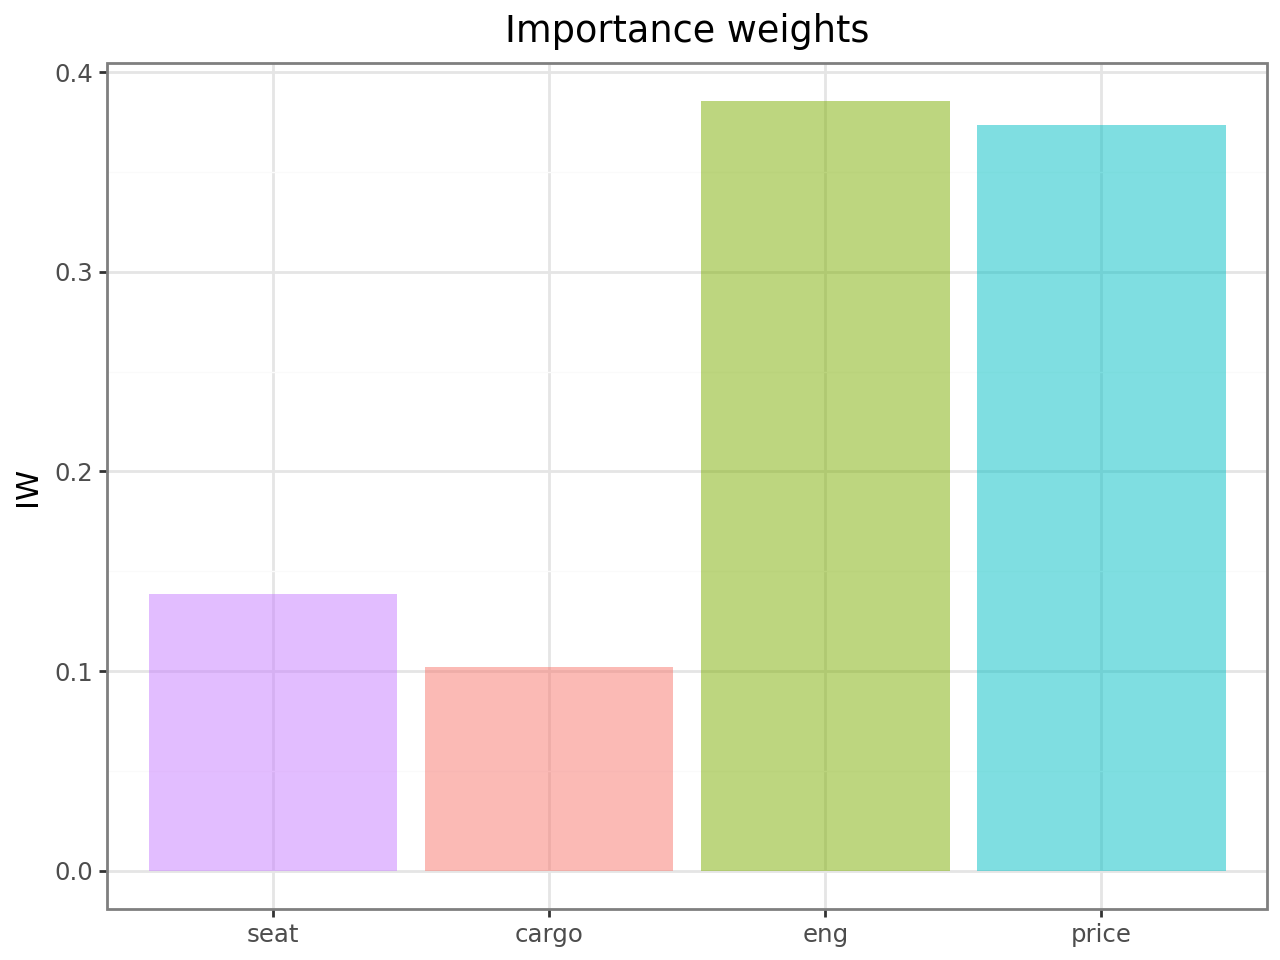

In [15]:
cc.plot(plots="iw")

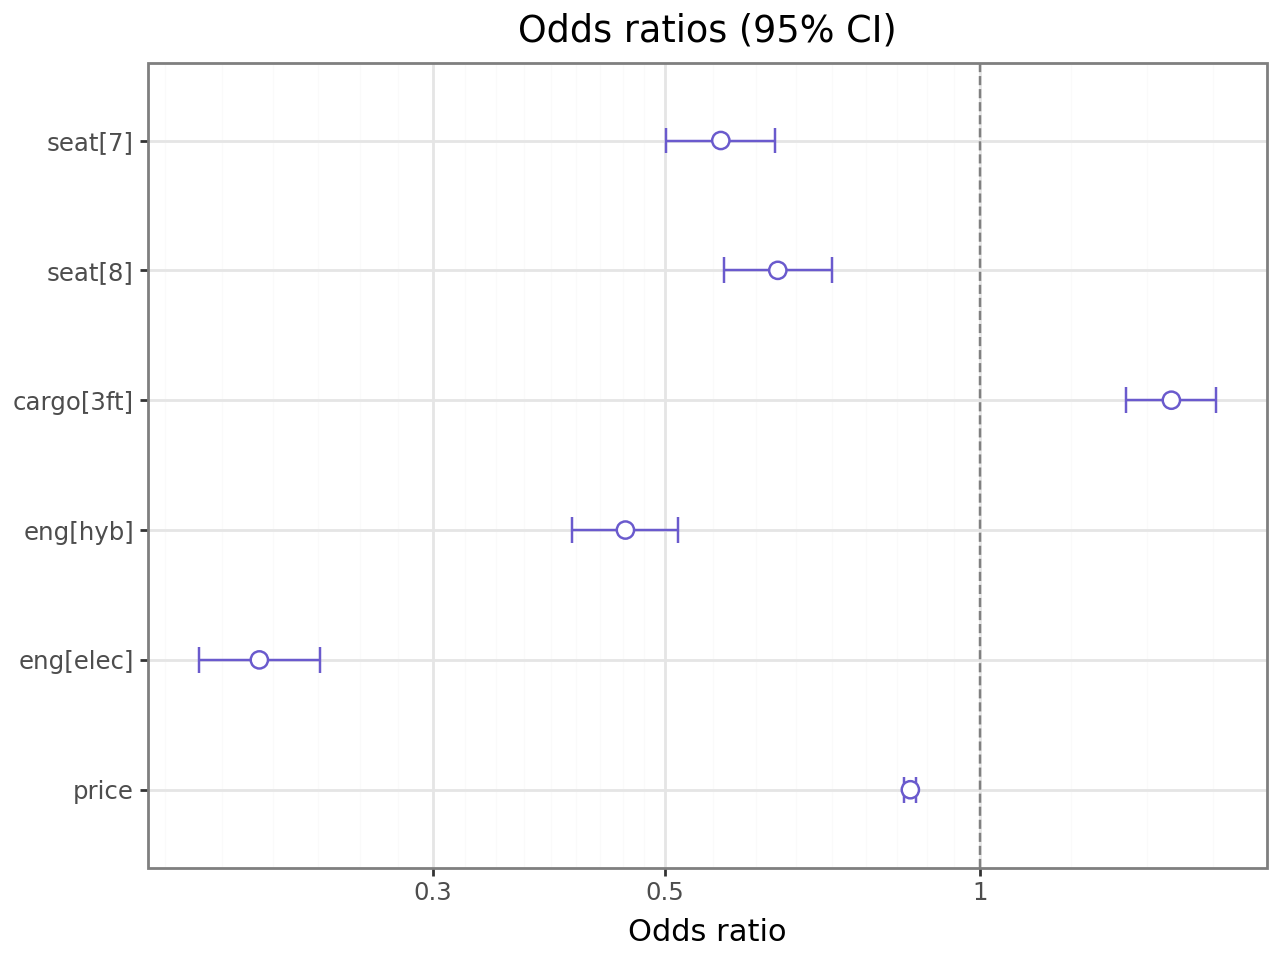

In [16]:
cc.plot(plots="or", conf=0.95)

## f. Segments: Do Carpoolers Value Seating Differently?

Respondents who carpool need room for more passengers. Estimate the model for each segment separately with `data_filter` (in Radiant-AI: the *Data scope* filter in *Data > View*):

In [17]:
seg = {}
for c in ["yes", "no"]:
    seg[c] = rsm.multivariate.conjoint_choice(
        {"minivan": minivan},
        rvar="choice",
        lev="1",
        evar=["seat", "cargo", "eng", "price"],
        id="task",
        alt="alt",
        data_filter=f"carpool == '{c}'",
    )
seg["yes"].summary()

Conjoint choice model (conditional logit)
Data                 : minivan
Filter               : carpool == 'yes'
Response variable    : choice
Level                : 1
Choice task id       : task
Alternative id       : alt
Explanatory variables: seat, cargo, eng, price
Null hyp.: There is no effect of x on the choice of choice
Alt. hyp.: There is an effect of x on the choice of choice

┌────────────┬───────┬────────┬─────────────┬───────────┬─────────┬─────────┬─────┐
│ index      ┆ OR    ┆ OR%    ┆ coefficient ┆ std.error ┆ z.value ┆ p.value ┆     │
╞════════════╪═══════╪════════╪═════════════╪═══════════╪═════════╪═════════╪═════╡
│ seat[7]    ┆ 1.626 ┆ 62.6%  ┆ 0.486       ┆ 0.128     ┆ 3.783   ┆ < .001  ┆ *** │
│ seat[8]    ┆ 2.153 ┆ 115.3% ┆ 0.767       ┆ 0.131     ┆ 5.833   ┆ < .001  ┆ *** │
│ cargo[3ft] ┆ 1.351 ┆ 35.1%  ┆ 0.301       ┆ 0.105     ┆ 2.864   ┆ 0.004   ┆ **  │
│ eng[hyb]   ┆ 0.478 ┆ -52.2% ┆ -0.737      ┆ 0.124     ┆ -5.966  ┆ < .001  ┆ *** │
│ eng[elec]  ┆ 0.269 ┆ 

Compare the willingness to pay of the two segments side by side:

In [18]:
seg["yes"].wtp(dec=2).rename({"PW": "PW_carpool", "WTP": "WTP_carpool"}).join(
    seg["no"].wtp(dec=2).rename({"PW": "PW_other", "WTP": "WTP_other"}),
    on=["Attributes", "Levels"],
)

Attributes,Levels,PW_carpool,WTP_carpool,PW_other,WTP_other
str,str,f64,f64,f64,f64
"""seat""","""6""",0.0,0.0,0.0,0.0
"""seat""","""7""",0.49,3.49,-0.92,-5.64
"""seat""","""8""",0.77,5.5,-0.83,-5.11
"""cargo""","""2ft""",0.0,0.0,0.0,0.0
"""cargo""","""3ft""",0.3,2.16,0.47,2.88
"""eng""","""gas""",0.0,0.0,0.0,0.0
"""eng""","""hyb""",-0.74,-5.29,-0.83,-5.14
"""eng""","""elec""",-1.31,-9.43,-1.76,-10.83


Carpoolers (675 tasks) prefer 7 seats (PW +0.49) and 8 seats (+0.77) over 6, worth about \$3,500 and \$5,500. Non-carpoolers strongly prefer 6 seats (7 seats −0.92, 8 seats −0.83, a WTP of about −\$5,600 and −\$5,100). The pooled model in **a** averaged two opposite preferences: a product line with a 6-seat model for most buyers and an 8-seat model for carpoolers can serve both segments.

How different are the market shares? Predict `minivan_market` with each segment's model:

In [19]:
minivan_market.select("product", "seat", "eng", "price").with_columns(
    carpool=seg["yes"].predict(minivan_market, dec=3)["prediction"],
    other=seg["no"].predict(minivan_market, dec=3)["prediction"],
)

product,seat,eng,price,carpool,other
i64,enum,enum,i32,f64,f64
1,"""7""","""hyb""",30,0.158,0.094
2,"""6""","""gas""",30,0.203,0.541
3,"""8""","""gas""",30,0.437,0.236
4,"""7""","""gas""",40,0.111,0.068
5,"""6""","""elec""",40,0.014,0.018
6,"""7""","""hyb""",35,0.079,0.042


The 8-seat gas minivan (product 3) is the clear favorite of carpoolers, while non-carpoolers mostly choose the 6-seat gas minivan (product 2). With about 30% carpoolers, the overall shares are close to a weighted average of the two columns.

A more complete approach estimates a separate set of part-worths for every respondent (a hierarchical Bayes or mixed logit model, see Chapman and Feit, section 13.5) and then clusters respondents on their part-worths. Segmenting on a known variable such as `carpool` is the simple first step.

## g. The Limits of the Logit Model: IIA

The conditional logit assumes the **independence of irrelevant alternatives** (IIA): the ratio of the shares of two products does not depend on which other products are in the market. Add an exact copy of the market leader (product 2) and see what happens:

In [20]:
with_copy = pl.concat([minivan_market, minivan_market.filter(pl.col("product") == 2).with_columns(product=pl.lit(7, dtype=pl.Int64))])
with_copy.select("product").with_columns(
    before=pl.concat([shares["prediction"], pl.Series([None], dtype=pl.Float64)]),
    after=cc.predict(with_copy, dec=3)["prediction"],
)

product,before,after
i64,f64,f64
1,0.115,0.08
2,0.445,0.308
3,0.285,0.197
4,0.082,0.057
5,0.02,0.014
6,0.053,0.037
7,null,0.308


The copy gets as much share as the original (30.8% each), so together they get 61.6%, up from 44.5%. The logit model takes that share from **every** product in proportion to its share: every other product loses 31% of its share. In reality, a near-identical minivan would mostly take share from the product it copies, so the two together would get little more than the original alone. Keep this in mind when simulating line extensions or me-too products: the logit model overstates the share of products that are similar to existing ones.

## Store Results

`store` returns the part-worths (`"PW"`), importance weights (`"IW"`), willingness to pay (`"WTP"`) or the coefficient table (`"coef"`) as a data frame, e.g., to save or chart them. None of this changes `minivan` itself.

In [21]:
cc.store("WTP", price="price")

Attributes,Levels,PW,WTP
str,str,f64,f64
"""seat""","""6""",0.0,0.0
"""seat""","""7""",-0.570436,-3.712461
"""seat""","""8""",-0.445111,-2.896834
"""cargo""","""2ft""",0.0,0.0
"""cargo""","""3ft""",0.420322,2.735501
"""eng""","""gas""",0.0,0.0
"""eng""","""hyb""",-0.780185,-5.077535
"""eng""","""elec""",-1.585133,-10.316227


## Discussion Prompts

- Which attribute matters most for choice? Would the answer change if the study had tested prices from \$25K to \$45K?
- The new hybrid gets 11.5% at \$30K. What would you change about the design to raise its share, and what is each change worth in dollars?
- Carpoolers and other buyers want different minivans. How large must the carpool segment be to justify an 8-seat model?
- Why might predicted shares differ from actual market shares (awareness, distribution, a "buy none" option, IIA)?

Source: the study design follows Chapman, C. and Feit, E. M. (2019), *R for Marketing Research and Analytics*, 2nd ed., Springer, chapter 13 ([chapter 13 code](https://r-marketing.r-forge.r-project.org/Instructor/Chapter13/Chapter13-ChapmanFeit.html)). The data are simulated.